### Import Modules

In [1]:
import numpy as np
import pandas as pd
import os, sys, re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from pathlib import Path
import glob
from scipy.stats import zscore

try:
    import utils.segment_isc_utils
except ImportError as e:
    print(f"\nSTILL FAILING: {e}")

### Set up helper functions

In [2]:
current_dir = os.getcwd()
DATA_DIR        = os.path.abspath(os.path.join(current_dir, "../data/02_processed_combined_data"))
CONDITIONS_FILE = os.path.abspath(os.path.join(current_dir, "../data/sub_conditions.csv"))
OUTPUT_DIR      = os.path.abspath(os.path.join(current_dir, "../data/04_analysis/segmented"))

def get_signal_data(signal):
    pc_subs  = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PC')
    pcm_subs = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PCM')
                            
    df_pc  = utils.segment_isc_utils.load_physio_data(DATA_DIR, pc_subs, signal_type=signal)
    df_pcm = utils.segment_isc_utils.load_physio_data(DATA_DIR, pcm_subs, signal_type=signal)
                
    # Ensure same length (trim to min)
    l_pc = df_pc.shape[0]
    l_pcm = df_pcm.shape[0]
    common_len = min(l_pc, l_pcm)
            
    df_pc = df_pc.iloc[:common_len]
    df_pcm = df_pcm.iloc[:common_len]
    
    return df_pc, df_pcm



def sliding_window_isc(data, sampling_rate=20, window_sec=10, step_sec=1):
    """
    Computes sliding window ISC for data organized as (Time, Subjects).
    
    Parameters:
    -----------
    data: numpy array of shape (n_samples, n_subjects)
          Rows = Time points (samples)
          Columns = Subjects
    sampling_rate: Hz (20 in your case)
    window_sec: size of the window in seconds
    step_sec: how much to move the window each iteration
    """
    
    # 1. CHANGE: Unpack shape assuming (samples, subjects)
    n_samples, n_subjects = data.shape
    
    # Convert seconds to samples
    window_samples = int(window_sec * sampling_rate)
    step_samples = int(step_sec * sampling_rate)
    
    # Calculate number of windows
    n_windows = int((n_samples - window_samples) / step_samples) + 1
    
    isc_values = []
    time_indices = []

    # --- PRE-PROCESSING ---
    # 2. CHANGE: Standardize data (Z-score) across TIME (rows).
    # We use axis=0 so that every column (subject) has mean=0, std=1 over the full duration.
    clean_data = zscore(data, axis=0)

    # --- SLIDING WINDOW LOOP ---
    for i in range(n_windows):
        start_idx = i * step_samples
        end_idx = start_idx + window_samples
        
        # 3. CHANGE: Extract the chunk by slicing ROWS
        # Shape becomes (window_samples, n_subjects)
        chunk = clean_data[start_idx:end_idx, :]
        
        # --- LEAVE-ONE-OUT ISC CALCULATION ---
        window_correlations = []
        
        for subj in range(n_subjects):
            # 4. CHANGE: Extract specific subject COLUMN
            subject_ts = chunk[:, subj]
            
            # 5. CHANGE: Delete the subject column (axis=1) to get the others
            others = np.delete(chunk, subj, axis=1)
            
            # 6. CHANGE: Average across the remaining subjects (axis=1)
            # This results in a 1D array of shape (window_samples,)
            group_average_ts = np.mean(others, axis=1)
            
            # Pearson Correlation
            # np.corrcoef returns a 2x2 matrix, we want the off-diagonal
            r = np.corrcoef(subject_ts, group_average_ts)[0, 1]
            
            # Handle potential NaNs if a window is perfectly flat (variance = 0)
            if np.isnan(r):
                r = 0 
                
            # Fisher Z-transform
            # We clip r slightly to avoid infinity if r is exactly 1 or -1
            r = np.clip(r, -0.999999, 0.999999)
            z = np.arctanh(r) 
            window_correlations.append(z)
        
        # Average the Z-values for this window across all subjects
        avg_z = np.mean(window_correlations)
        
        # Convert back to R
        avg_r = np.tanh(avg_z)
        
        isc_values.append(avg_r)
        
        # Store center timepoint
        center_time_sec = (start_idx + end_idx) / 2 / sampling_rate
        time_indices.append(center_time_sec)

    return time_indices, isc_values

### Load data and plot

97
97


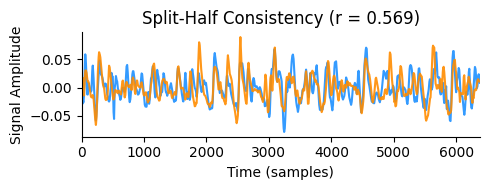

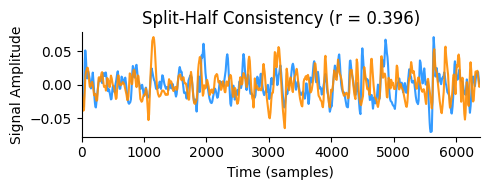

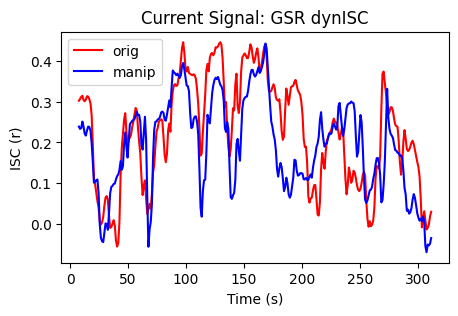

97
97


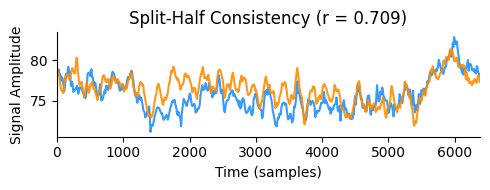

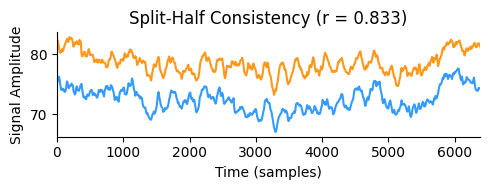

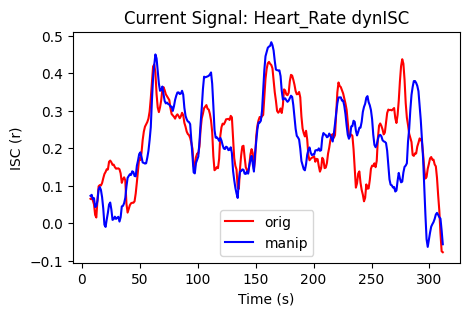

97
97


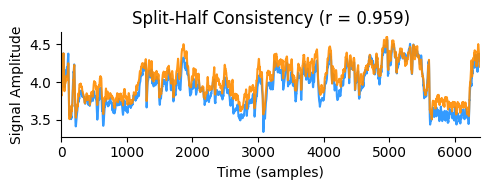

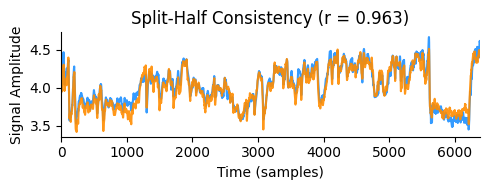

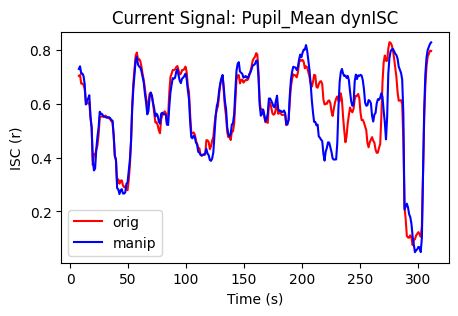

97
97


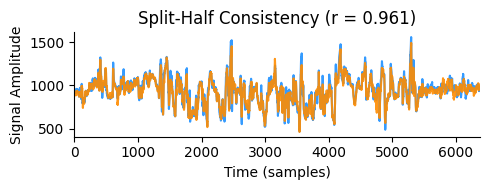

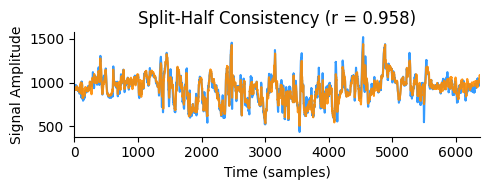

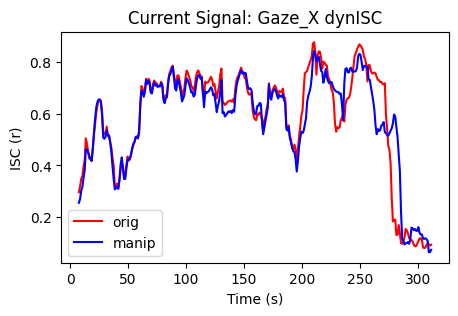

97
97


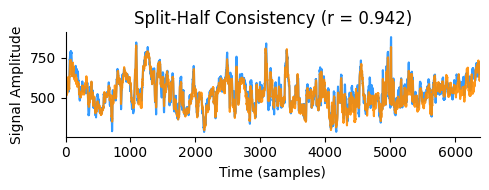

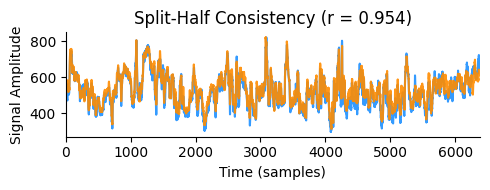

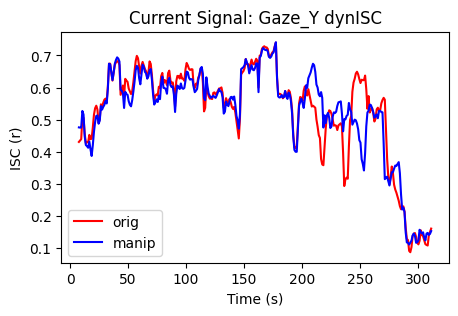

In [3]:
isc_origs = []
isc_manips = []
lotris = []
lotrisM = []

signals = ['GSR', 'Heart_Rate',  'Pupil_Mean', 'Gaze_X', 'Gaze_Y']

for signal in signals:
    
    df_pc_orig, df_pcm_manip      = get_signal_data(signal)
    print(df_pc_orig.shape[1])
    print(df_pcm_manip.shape[1])
    
    utils.segment_isc_utils.plot_split_half_comparison(df_pc_orig)
    utils.segment_isc_utils.plot_split_half_comparison(df_pcm_manip)
    
    time_orig, isc_orig = sliding_window_isc(df_pc_orig.values, window_sec=15)
    time_manip, isc_manip = sliding_window_isc(df_pcm_manip.values, window_sec=15)
    
    plt.figure(figsize = (5,3))
    plt.plot(time_orig, isc_orig, label='orig', color = 'r')
    plt.plot(time_manip, isc_manip, label='manip', color = 'b')
    plt.xlabel('Time (s)')
    plt.ylabel('ISC (r)')
    plt.legend()
    current_title = 'Current Signal: ' + signal + ' dynISC'
    plt.title(current_title)
    plt.show()

    isc_origs.append(isc_orig)
    isc_manips.append(isc_manip)

    #$ correlations and lower triangular
    res = np.corrcoef(df_pc_orig.values.T)
    rows, cols = np.tril_indices(res.shape[0],  k=-1) 
    vectorized_lower = res[rows, cols]
    vectorized_lower.shape

    lotris.append(vectorized_lower)

    #$ correlations and lower triangular
    res = np.corrcoef(df_pcm_manip.values.T)
    rows, cols = np.tril_indices(res.shape[0],  k=-1) 
    vectorized_lower = res[rows, cols]
    vectorized_lower.shape

    lotrisM.append(vectorized_lower)

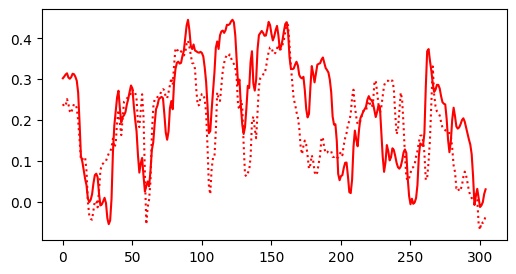

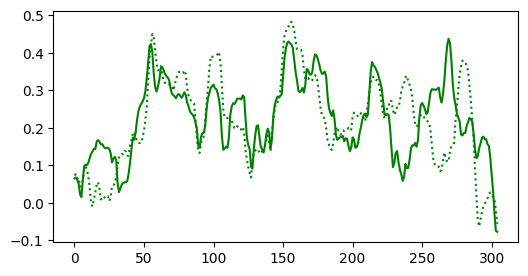

In [4]:
plt.figure(figsize = (6,3))
plt.plot(isc_origs[0], 'r')
plt.plot(isc_manips[0], 'r:')
plt.show()

plt.figure(figsize = (6,3))
plt.plot(isc_origs[1], 'g')
plt.plot(isc_manips[1], 'g:')

#plt.plot(isc_origs[2], 'g')
#plt.plot(isc_origs[3], 'g')
#plt.plot(isc_origs[4], 'b')


In [5]:
np.corrcoef(isc_origs[0], isc_origs[1])

array([[1.        , 0.36442702],
       [0.36442702, 1.        ]])

In [8]:
ltrs = np.asarray(lotris)
print(ltrs.shape)

ltrsM = np.asarray(lotrisM)
print(ltrsM.shape)


(5, 4656)
(5, 4656)


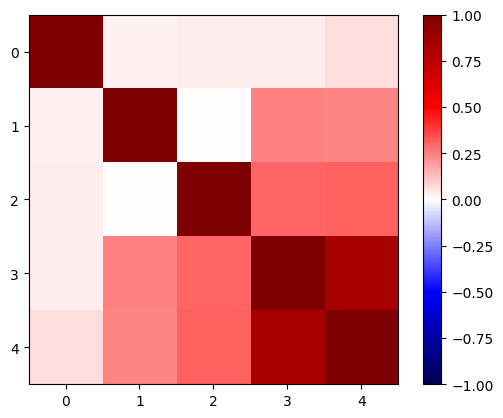

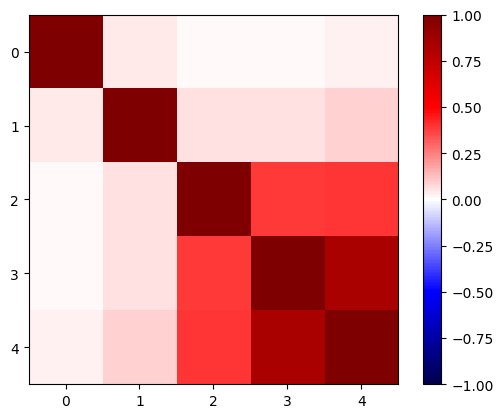

In [11]:
plt.imshow(np.corrcoef(ltrs), cmap = 'seismic', vmin=-1, vmax =1)
plt.colorbar()
plt.show()

plt.imshow(np.corrcoef(ltrsM), cmap = 'seismic', vmin=-1, vmax =1)
plt.colorbar()



In [14]:
a = 3
b = 0

#plt.figure(figsize = (5,5))
#plt.scatter(ltrs[a,:], ltrs[b,:])
print(np.corrcoef(ltrs[a,:], ltrs[b,:])[0,1])
#plt.xlabel('gaze')
#plt.ylabel('heart')
#plt.show()

#plt.figure(figsize = (5,5))
#plt.scatter(ltrsM[a,:], ltrsM[b,:])
print(np.corrcoef(ltrsM[a,:], ltrsM[b,:])[0,1])
#plt.xlabel('gaze')
#plt.ylabel('heart')
#plt.show()

0.03209678675353352
0.008194808525332302


In [102]:
df_pcm_manip

,sub001,sub006,sub007,sub008,sub011,sub013,sub014,sub016,sub019,sub020,...,sub183,sub185,sub190,sub192,sub195,sub200,sub201,sub202,sub206,sub207
0,0.001461,0.027743,0.005550,0.000366,0.001922,0.006214,0.028150,-0.011353,0.001013,-0.027315,...,0.000757,-0.020813,-0.010400,0.022394,-0.015563,-0.001743,0.009765,0.002309,0.003265,0.014818
1,0.001146,0.028076,0.005990,0.000381,-0.001264,0.007199,0.028400,-0.005764,0.000809,-0.033868,...,0.001426,-0.024374,-0.009173,0.022186,-0.017735,-0.000468,0.008569,0.002261,0.003635,0.016405
2,0.000830,0.028408,0.006431,0.000396,-0.004450,0.008184,0.028650,-0.000174,0.000604,-0.040421,...,0.002095,-0.027934,-0.007946,0.021979,-0.019907,0.000807,0.007373,0.002213,0.004005,0.017993
3,0.000515,0.028741,0.006872,0.000411,-0.007637,0.009169,0.028900,0.005415,0.000399,-0.046974,...,0.002764,-0.031494,-0.006719,0.021772,-0.022080,0.002083,0.006177,0.002165,0.004374,0.019580
4,0.000200,0.029073,0.007313,0.000427,-0.010823,0.010153,0.029150,0.011004,0.000195,-0.053526,...,0.003434,-0.035054,-0.005493,0.021564,-0.024252,0.003358,0.004981,0.002116,0.004744,0.021168
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6376,0.012001,0.170248,-0.001713,-0.000091,0.040218,-0.021546,0.021992,-0.008574,0.004089,-0.008328,...,-0.066749,-0.014979,-0.000593,-0.009540,-0.008803,-0.015224,0.082615,0.004526,-0.005833,-0.024888
6377,0.011645,0.151911,-0.001867,-0.000095,0.039876,-0.020947,0.022706,0.000493,0.003849,-0.008322,...,-0.057221,-0.013407,-0.000836,-0.008115,-0.007759,-0.015304,0.076054,0.004282,-0.005508,-0.022070
6378,0.011289,0.133574,-0.002021,-0.000100,0.039535,-0.020347,0.023420,0.009559,0.003610,-0.008317,...,-0.047692,-0.011834,-0.001080,-0.006690,-0.006715,-0.015385,0.069493,0.004037,-0.005183,-0.019252
6379,0.010933,0.115237,-0.002175,-0.000104,0.039193,-0.019748,0.024133,0.018626,0.003370,-0.008312,...,-0.038164,-0.010261,-0.001323,-0.005265,-0.005672,-0.015465,0.062932,0.003793,-0.004858,-0.016434


In [127]:
df_pc_orig.shape

(6381, 97)